# ACF & PACF (Autocorrelation Plots)

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Shows how strongly a time series is correlated with its own past. The autocorrelation function (ACF) shows the correlation at each lag; the partial autocorrelation function (PACF) shows each lag's correlation after removing the effect of shorter lags. Bars outside the confidence band reveal memory and seasonality, and their pattern suggests which ARIMA-type model fits.

## When to use

- Check for seasonality and its period (spikes at lags 7, 12, 52…)
- Choose AR and MA orders before fitting a forecasting model
- Test whether model residuals are white noise (no bars should cross the band)

## Avoid when

- The series has a strong trend (difference or detrend it first, or every lag looks significant)
- The audience is non-technical (show the seasonal pattern directly instead)

## Alternatives

- Seasonal cycle plot
- STL decomposition
- Lag scatter plot (y_t vs. y_t−k)

## Design tips

- Always draw the confidence band (approx. ±1.96/√n)
- Show the series itself above the correlograms so readers see what is being measured
- Mark the expected seasonal lags

## Example

365 days of simulated website sessions (detrended): an AR(1) process with a weekly pattern, as traffic dips every weekend.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from statsmodels.tsa.stattools import acf, pacf

### Data

In [2]:
rng = np.random.default_rng(9)
n = 365
dates = pd.date_range("2024-01-01", periods=n, freq="D")
weekly = np.array([0.4, 0.5, 0.5, 0.45, 0.3, -1.1, -1.05])      # Mon..Sun effect
x = np.zeros(n)
for t in range(1, n):
    x[t] = 0.55 * x[t - 1] + rng.normal(0, 0.6)
series = pd.Series(x + weekly[dates.dayofweek], index=dates, name="sessions (std. units)")
nlags = 28
series.head(8).round(2)

2024-01-01    0.40
2024-01-02    0.02
2024-01-03    0.38
2024-01-04   -0.61
2024-01-05    0.11
2024-01-06   -0.52
2024-01-07   -1.00
2024-01-08    0.69
Freq: D, Name: sessions (std. units), dtype: float64

### Plot

/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_17760/2769933264.py:11: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  else fn(series, nlags=nlags, alpha=0.05, fft=True))


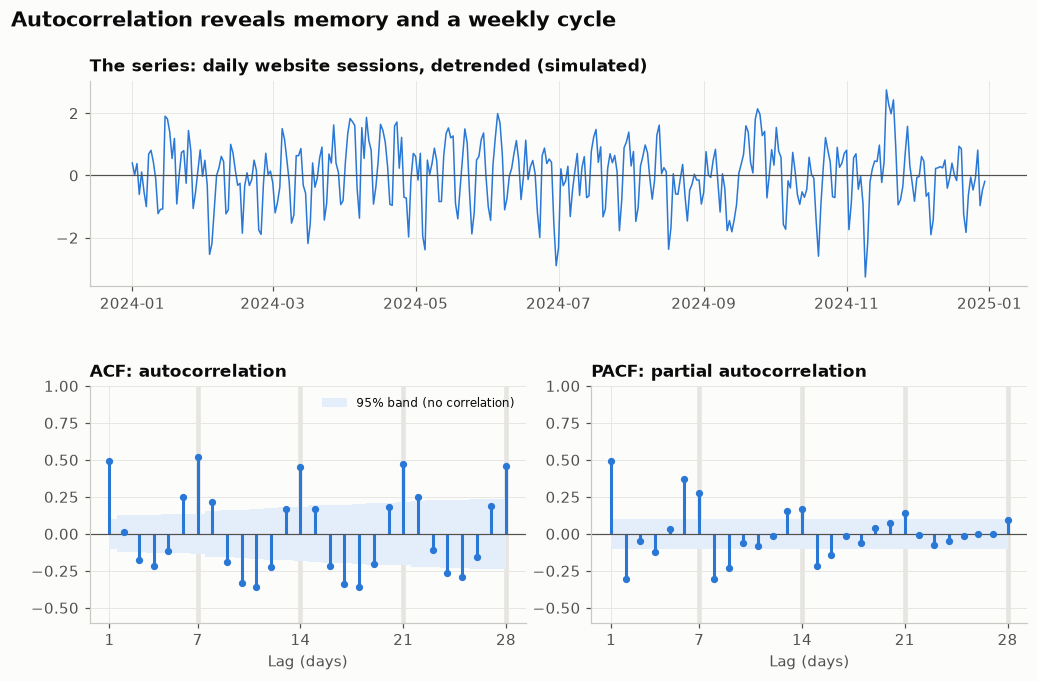

In [3]:
fig = plt.figure(figsize=(11, 6.4))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=0.45, wspace=0.15)
ax0 = fig.add_subplot(gs[0, :])
ax0.plot(series.index, series, color=PALETTE[0], linewidth=1)
ax0.axhline(0, color="#52514e", linewidth=0.8)
ax0.set_title("The series: daily website sessions, detrended (simulated)", fontsize=11)

for k, (name, fn) in enumerate([("ACF: autocorrelation", acf), ("PACF: partial autocorrelation", pacf)]):
    ax = fig.add_subplot(gs[1, k], sharey=None)
    vals, ci = (fn(series, nlags=nlags, alpha=0.05) if fn is pacf
                else fn(series, nlags=nlags, alpha=0.05, fft=True))
    lags = np.arange(len(vals))
    band = ci[:, 1] - vals
    ax.fill_between(lags[1:], -band[1:], band[1:], color="#e4eefb", step="mid", linewidth=0,
                    label="95% band (no correlation)")
    ax.vlines(lags[1:], 0, vals[1:], color=PALETTE[0], linewidth=2)
    ax.scatter(lags[1:], vals[1:], color=PALETTE[0], s=14, zorder=3)
    ax.axhline(0, color="#52514e", linewidth=0.8)
    for s in (7, 14, 21, 28):
        ax.axvline(s, color="#e6e5e1", linewidth=3, zorder=0)
    ax.set_xticks([1, 7, 14, 21, 28])
    ax.set_xlabel("Lag (days)")
    ax.set_ylim(-0.6, 1)
    ax.set_title(name, fontsize=11)
    if k == 0:
        ax.legend(loc="upper right", fontsize=8)
fig.suptitle("Autocorrelation reveals memory and a weekly cycle", x=0.06, ha="left",
             fontsize=14, fontweight="bold")
plt.show()

## How to read it

The ACF decays slowly with spikes at lags 7, 14 and 21, so there is short-term memory plus a weekly cycle. The PACF has a large bar at lag 1 and another near lag 7, then mostly stays inside the band. A model with one autoregressive term and a weekly seasonal term should fit.

---
Standalone script: [`acf_pacf.py`](acf_pacf.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)